<a href="https://colab.research.google.com/github/franck2908/IBM-Applied-Data-Science-Capstone/blob/main/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IBM Applied Data Science Capstone
## SpaceX Falcon 9 First Stage Landing Prediction

### Project Overview
The objective of this project is to predict whether the first stage of a SpaceX Falcon 9 rocket will land successfully.

### Data Sources
- SpaceX REST API
- Wikipedia launch records

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SQL
- Folium
- Plotly Dash

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import requests

urls = [
    "https://api.spacexdata.com/v4/launches/latest",
    "https://api.spacexdata.com/v3/launches"
]

launches = None

for url in urls:
    try:
        print("Test :", url)

        response = requests.get(url, timeout=30)

        print("Status :", response.status_code)

        if response.status_code == 200:
            data = response.json()

            if isinstance(data, list):
                launches = data
            else:
                launches = [data]

            print("Connexion réussie !")
            print("Nombre de résultats :", len(launches))
            break

    except requests.exceptions.RequestException as e:
        print("Erreur :", e)

if launches is None:
    print("Les deux adresses sont inaccessibles depuis Colab.")

Test : https://api.spacexdata.com/v4/launches/latest
Status : 522
Test : https://api.spacexdata.com/v3/launches
Status : 522
Les deux adresses sont inaccessibles depuis Colab.


In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/savio-kenneth-myers/SpaceX-Capstone-Project/main/dataset_part_1.csv"

df = pd.read_csv(url)

print("Dataset chargé avec succès")
print("Dimensions :", df.shape)
display(df.head())


Dataset chargé avec succès
Dimensions : (182, 17)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04T18:45:00.000Z,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2010-12-08T15:43:00.000Z,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0004,-80.577366,28.561857
2,3,2012-05-22T07:44:00.000Z,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
3,4,2012-10-08T00:35:00.000Z,Falcon 9,400.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0006,-80.577366,28.561857
4,5,2013-03-01T19:10:00.000Z,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857


In [ ]:

# 1. Examiner les informations du dataset
print("Dimensions :", df.shape)

print("\nInformations générales :")
df.info()

# 2. Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
display(df.isnull().sum())

# 3. Vérifier les doublons
print("\nNombre de doublons :", df.duplicated().sum())

# 4. Afficher les premières lignes
display(df.head(10))


Dimensions : (182, 17)

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    182 non-null    int64  
 1   Date            182 non-null    object 
 2   BoosterVersion  182 non-null    object 
 3   PayloadMass     182 non-null    float64
 4   Orbit           182 non-null    object 
 5   LaunchSite      182 non-null    object 
 6   Outcome         182 non-null    object 
 7   Flights         182 non-null    int64  
 8   GridFins        182 non-null    bool   
 9   Reused          182 non-null    bool   
 10  Legs            182 non-null    bool   
 11  LandingPad      151 non-null    object 
 12  Block           182 non-null    float64
 13  ReusedCount     182 non-null    int64  
 14  Serial          182 non-null    object 
 15  Longitude       182 non-null    float64
 16  Latitude        182 non-null   

,0
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0



Nombre de doublons : 0


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04T18:45:00.000Z,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2010-12-08T15:43:00.000Z,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0004,-80.577366,28.561857
2,3,2012-05-22T07:44:00.000Z,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
3,4,2012-10-08T00:35:00.000Z,Falcon 9,400.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0006,-80.577366,28.561857
4,5,2013-03-01T19:10:00.000Z,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
5,6,2013-09-29T16:00:00.000Z,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
6,7,2013-12-03T22:41:00.000Z,Falcon 9,3170.000000,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857
7,8,2014-01-06T18:06:00.000Z,Falcon 9,3325.000000,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1005,-80.577366,28.561857
8,9,2014-04-18T19:25:00.000Z,Falcon 9,2296.000000,ISS,CCSFS SLC 40,True Ocean,1,False,False,True,NaN,1.0,0,B1006,-80.577366,28.561857
9,10,2014-07-14T15:15:00.000Z,Falcon 9,1316.000000,LEO,CCSFS SLC 40,True Ocean,1,False,False,True,NaN,1.0,0,B1007,-80.577366,28.561857


In [ ]:

# Vérification des doublons
print("Doublons avant nettoyage :", df.duplicated().sum())

# Conversion de la colonne Date
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Traitement des valeurs manquantes
df["LandingPad"] = df["LandingPad"].fillna("Unknown")

# Vérification après nettoyage
print("\nValeurs manquantes après nettoyage :")
display(df.isnull().sum())

print("\nDimensions finales :", df.shape)
print("Doublons après nettoyage :", df.duplicated().sum())

display(df.head())



Doublons avant nettoyage : 0

Valeurs manquantes après nettoyage :


,0
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0



Dimensions finales : (182, 17)
Doublons après nettoyage : 0


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04 18:45:00+00:00,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0003,-80.577366,28.561857
1,2,2010-12-08 15:43:00+00:00,Falcon 9,8014.412264,LEO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0004,-80.577366,28.561857
2,3,2012-05-22 07:44:00+00:00,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0005,-80.577366,28.561857
3,4,2012-10-08 00:35:00+00:00,Falcon 9,400.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0006,-80.577366,28.561857
4,5,2013-03-01 19:10:00+00:00,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0007,-80.577366,28.561857


In [ ]:

# Statistiques descriptives
display(df.describe(include="all"))

# Nombre de lancements par site
print("Lancements par site :")
display(df["LaunchSite"].value_counts())

# Résultats des atterrissages
print("Résultats des atterrissages :")
display(df["Outcome"].value_counts())

# Année de lancement
df["Year"] = df["Date"].dt.year

print("Lancements par année :")
display(df["Year"].value_counts().sort_index())


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
count,182.000000,182,182,182.000000,182,182,182,182.000000,182,182,182,182,182.000000,182.000000,182,182.000000,182.000000
unique,NaN,NaN,2,NaN,13,3,8,NaN,2,2,2,7,NaN,NaN,69,NaN,NaN
top,NaN,NaN,Falcon 9,NaN,VLEO,CCSFS SLC 40,True ASDS,NaN,True,True,True,5e9e3032383ecb6bb234e7ca,NaN,NaN,B1058,NaN,NaN
freq,NaN,NaN,179,NaN,59,99,115,NaN,159,115,158,64,NaN,NaN,14,NaN,NaN
mean,91.500000,2019-08-17 03:42:55.329670144+00:00,NaN,8014.412264,NaN,NaN,NaN,3.708791,NaN,NaN,NaN,NaN,4.148352,5.351648,NaN,-86.744396,29.509702
min,1.000000,2010-06-04 18:45:00+00:00,NaN,330.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,-120.610829,28.561857
25%,46.250000,2017-12-17 12:03:50.750000128+00:00,NaN,3208.750000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.250000,1.000000,NaN,-80.603956,28.561857
50%,91.500000,2020-06-22 02:38:00+00:00,NaN,8014.412264,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,5.000000,5.000000,NaN,-80.577366,28.561857
75%,136.750000,2021-12-19 00:08:55+00:00,NaN,13260.000000,NaN,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,5.000000,9.000000,NaN,-80.577366,28.608058
max,182.000000,2022-10-05 16:00:00+00:00,NaN,15600.000000,NaN,NaN,NaN,14.000000,NaN,NaN,NaN,NaN,5.000000,13.000000,NaN,-80.577366,34.632093


Lancements par site :


,count
LaunchSite,
CCSFS SLC 40,99
KSC LC 39A,55
VAFB SLC 4E,28


Résultats des atterrissages :


,count
Outcome,
True ASDS,115
None None,24
True RTLS,23
False ASDS,10
True Ocean,5
False Ocean,2
None ASDS,2
False RTLS,1


Lancements par année :


,count
Year,
2010,2
2012,2
2013,3
2014,6
2015,7
2016,9
2017,18
2018,21
2019,13


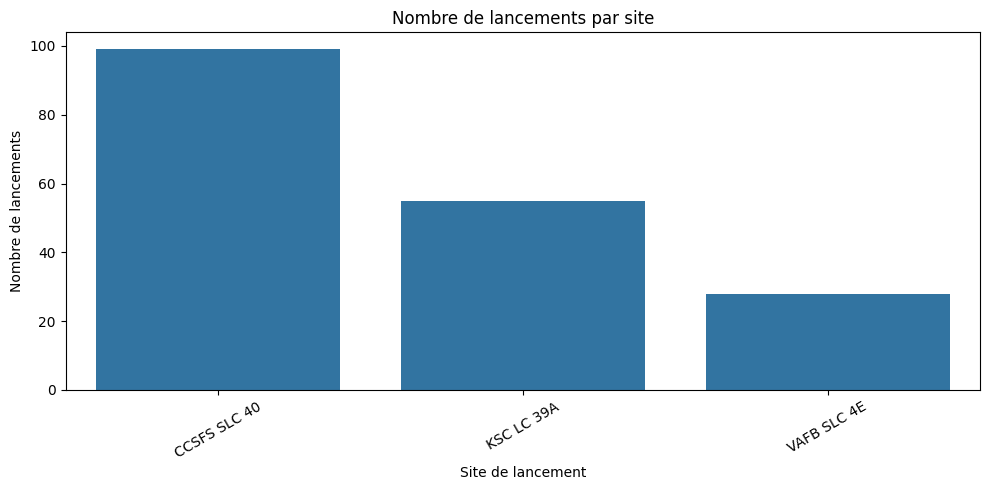

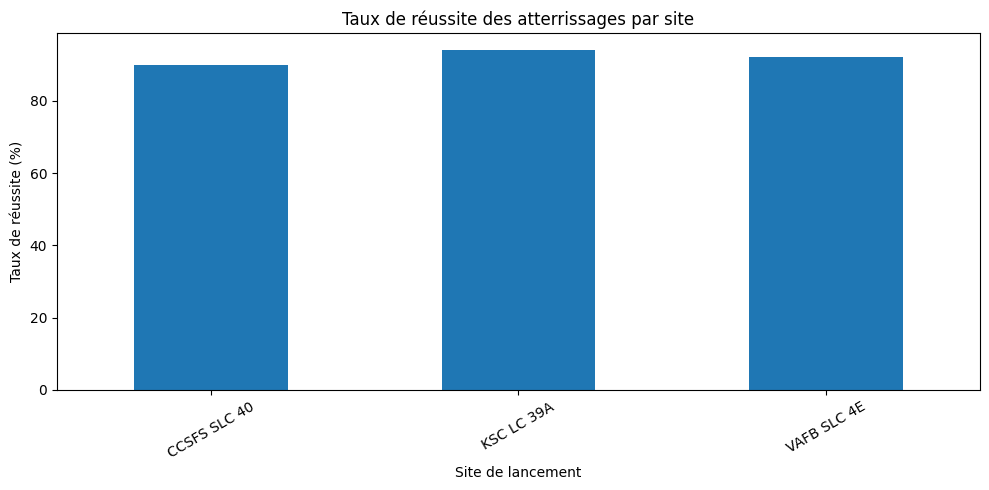

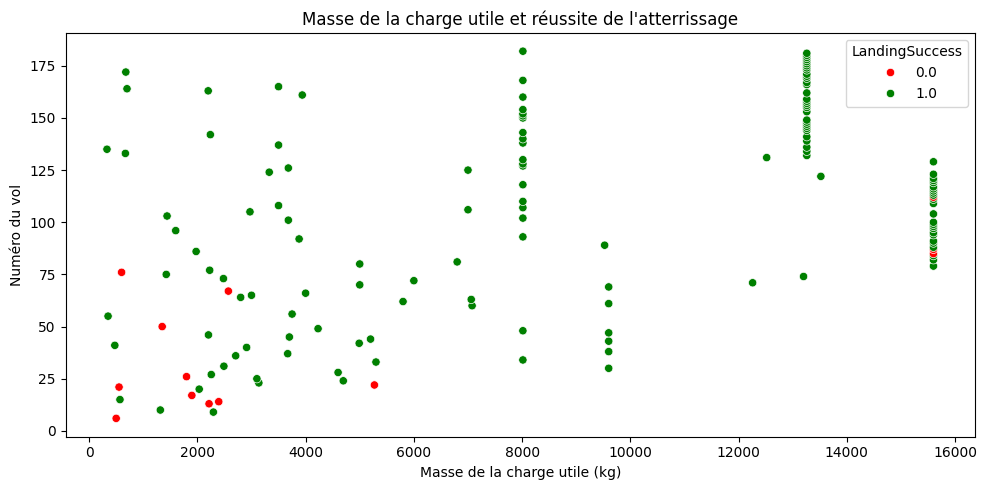

In [ ]:

# Identifier les réussites et les échecs
# Les résultats non confirmés restent manquants.
df["LandingSuccess"] = np.where(
    df["Outcome"].str.startswith("True"), 1,
    np.where(df["Outcome"].str.startswith("False"), 0, np.nan)
)

# Graphique 1 : lancements par site
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="LaunchSite",
              order=df["LaunchSite"].value_counts().index)
plt.title("Nombre de lancements par site")
plt.xlabel("Site de lancement")
plt.ylabel("Nombre de lancements")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Graphique 2 : taux de réussite par site
success_by_site = df.groupby("LaunchSite")["LandingSuccess"].mean() * 100

plt.figure(figsize=(10, 5))
success_by_site.plot(kind="bar")
plt.title("Taux de réussite des atterrissages par site")
plt.xlabel("Site de lancement")
plt.ylabel("Taux de réussite (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Graphique 3 : masse de la charge utile et réussite
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df.dropna(subset=["LandingSuccess"]),
    x="PayloadMass",
    y="FlightNumber",
    hue="LandingSuccess",
    palette={0: "red", 1: "green"}
)
plt.title("Masse de la charge utile et réussite de l'atterrissage")
plt.xlabel("Masse de la charge utile (kg)")
plt.ylabel("Numéro du vol")
plt.tight_layout()
plt.show()


In [ ]:

import sqlite3

# Création de la base de données
conn = sqlite3.connect(":memory:")

# Importer le DataFrame dans SQLite
df.to_sql("SPACEX", conn, if_exists="replace", index=False)

print("Base de données SPACEX créée avec succès !")


Base de données SPACEX créée avec succès !


In [ ]:

query = """
SELECT LaunchSite, COUNT(*) AS Nombre_Lancements
FROM SPACEX
GROUP BY LaunchSite
ORDER BY Nombre_Lancements DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,LaunchSite,Nombre_Lancements
0,CCSFS SLC 40,99
1,KSC LC 39A,55
2,VAFB SLC 4E,28


In [ ]:

query = """
SELECT Outcome, COUNT(*) AS Nombre
FROM SPACEX
GROUP BY Outcome
ORDER BY Nombre DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Outcome,Nombre
0,True ASDS,115
1,None None,24
2,True RTLS,23
3,False ASDS,10
4,True Ocean,5
5,None ASDS,2
6,False Ocean,2
7,False RTLS,1


In [ ]:

query = """
SELECT Orbit,
       ROUND(AVG(PayloadMass), 2) AS Masse_Moyenne
FROM SPACEX
GROUP BY Orbit
ORDER BY Masse_Moyenne DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Orbit,Masse_Moyenne
0,VLEO,14245.33
1,PO,8293.79
2,SO,8014.41
3,GEO,5976.21
4,LEO,5818.02
5,GTO,4887.94
6,ISS,4612.52
7,SSO,4012.30
8,MEO,3290.33
9,HCO,1350.00


In [ ]:

import folium

spacex_map = folium.Map(
    location=[29.5, -95],
    zoom_start=4,
    tiles=None
)

launch_sites = df[
    ["LaunchSite", "Latitude", "Longitude"]
].drop_duplicates()

for _, site in launch_sites.iterrows():
    folium.CircleMarker(
        location=[site["Latitude"], site["Longitude"]],
        radius=8,
        color="red",
        fill=True,
        fill_opacity=0.8,
        popup=site["LaunchSite"],
        tooltip=site["LaunchSite"]
    ).add_to(spacex_map)

# Enregistrer la carte
spacex_map.save("spacex_launch_sites.html")

spacex_map


In [6]:

!pip install plotly -q

import plotly.express as px

print("Plotly installé avec succès !")


Plotly installé avec succès !


In [7]:

fig = px.histogram(
    df,
    x="LaunchSite",
    color="LandingSuccess",
    title="Nombre de lancements par site et résultat d'atterrissage",
    labels={
        "LaunchSite": "Site de lancement",
        "LandingSuccess": "Réussite"
    },
    color_discrete_map={
        1.0: "green",
        0.0: "red"
    }
)

fig.show()


In [8]:

fig = px.scatter(
    df.dropna(subset=["LandingSuccess"]),
    x="PayloadMass",
    y="FlightNumber",
    color="LandingSuccess",
    title="Masse de la charge utile et réussite de l'atterrissage",
    labels={
        "PayloadMass": "Masse de la charge utile (kg)",
        "FlightNumber": "Numéro du vol",
        "LandingSuccess": "Réussite"
    },
    color_discrete_map={
        1.0: "green",
        0.0: "red"
    }
)

fig.show()


In [9]:

!pip install dash -q

print("Dash installé avec succès !")


Dash installé avec succès !


In [10]:

import plotly.express as px
from dash import Dash, dcc, html, Input, Output

# Créer l'application Dash
app = Dash(__name__)

# Liste des sites
sites = ["Tous les sites"] + sorted(df["LaunchSite"].unique())

# Interface du tableau de bord
app.layout = html.Div([
    html.H1("SpaceX Launch Records Dashboard"),

    html.Label("Sélectionner un site de lancement :"),

    dcc.Dropdown(
        id="site-dropdown",
        options=[{"label": s, "value": s} for s in sites],
        value="Tous les sites",
        clearable=False
    ),

    dcc.Graph(id="success-pie-chart"),

    dcc.Graph(id="payload-scatter-chart")
])

# Mise à jour des graphiques
@app.callback(
    [Output("success-pie-chart", "figure"),
     Output("payload-scatter-chart", "figure")],
    Input("site-dropdown", "value")
)
def update_dashboard(selected_site):

    filtered_df = df.dropna(subset=["LandingSuccess"]).copy()

    if selected_site != "Tous les sites":
        filtered_df = filtered_df[
            filtered_df["LaunchSite"] == selected_site
        ]

    pie_data = filtered_df["LandingSuccess"].value_counts().reset_index()
    pie_data.columns = ["LandingSuccess", "Count"]

    pie_fig = px.pie(
        pie_data,
        names="LandingSuccess",
        values="Count",
        title="Répartition des réussites et des échecs"
    )

    scatter_fig = px.scatter(
        filtered_df,
        x="PayloadMass",
        y="FlightNumber",
        color="LandingSuccess",
        title="Masse de la charge utile et résultat",
        labels={
            "PayloadMass": "Masse de la charge utile (kg)",
            "FlightNumber": "Numéro du vol"
        }
    )

    return pie_fig, scatter_fig

print("Tableau de bord Dash préparé avec succès !")


Tableau de bord Dash préparé avec succès !


In [11]:

from google.colab import output
import threading

# Démarrer le serveur Dash en arrière-plan
def run_dash():
    app.run(
        host="0.0.0.0",
        port=8050,
        debug=False
    )

thread = threading.Thread(target=run_dash, daemon=True)
thread.start()

# Afficher le tableau de bord dans Colab
output.serve_kernel_port_as_iframe(8050, height=800)



<IPython.core.display.Javascript object>

In [12]:

!pip install beautifulsoup4 requests lxml -q

from bs4 import BeautifulSoup
import requests
import pandas as pd

print("Bibliothèques installées !")


Bibliothèques installées !


In [13]:

url = "https://en.wikipedia.org/wiki/List_of_Falcon_9_and_Falcon_Heavy_launches"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; SpaceXCapstone/1.0)"
}

response = requests.get(url, headers=headers, timeout=30)

print("Status code :", response.status_code)

if response.status_code == 200:
    soup = BeautifulSoup(response.text, "html.parser")
    tables = soup.find_all("table", {"class": "wikitable"})
    print("Nombre de tableaux trouvés :", len(tables))
else:
    print("Impossible d'accéder à la page Web.")


Status code : 200
Nombre de tableaux trouvés : 4


In [14]:

if response.status_code == 200 and tables:
    scraped_tables = pd.read_html(response.text)

    print("Nombre de tableaux extraits :", len(scraped_tables))

    display(scraped_tables[0].head(10))
else:
    print("Aucun tableau exploitable trouvé.")


/tmp/ipykernel_2285/2293810401.py:2: FutureWarning:

Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.



Nombre de tableaux extraits : 19


,List of Falcon 9 and Falcon Heavy launches
0,2010–2019 · 2020–2022 · 2023 · 2024 · 2025 · 2...


In [15]:

from io import StringIO

scraped_tables = pd.read_html(StringIO(response.text))

for i, table in enumerate(scraped_tables):
    print(f"\nTABLEAU {i}")
    print("Dimensions :", table.shape)
    print("Colonnes :", list(table.columns))
    display(table.head(3))



TABLEAU 0
Dimensions : (1, 1)
Colonnes : ['List of Falcon 9 and Falcon Heavy launches']


,List of Falcon 9 and Falcon Heavy launches
0,2010–2019 · 2020–2022 · 2023 · 2024 · 2025 · 2...



TABLEAU 1
Dimensions : (331, 10)
Colonnes : ['Flight No.', 'Date and time (UTC)', 'Version, booster[i]', 'Launch site', 'Payload[j]', 'Payload mass', 'Orbit', 'Customer', 'Launch outcome', 'Booster landing']


,Flight No.,Date and time (UTC),"Version, booster[i]",Launch site,Payload[j],Payload mass,Orbit,Customer,Launch outcome,Booster landing
0,418,"January 4, 2025 01:27[29]",F9 B5 B1073‑20,"Cape Canaveral, SLC‑40",Thuraya 4-NGS,"5,000 kg (11,000 lb)",GTO,Thuraya,Success,Success (ASOG)
1,418,Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31],Planned replacement for Thuraya 2 and 3.[30][31]
2,419,"January 6, 2025 20:43[32]",F9 B5 B1077‑17,"Cape Canaveral, SLC‑40",Starlink: Group 6‑71,"~17,500 kg (38,600 lb)",LEO,SpaceX,Success,Success (JRTI)



TABLEAU 2
Dimensions : (262, 11)
Colonnes : ['Flight No.', 'Date and time (UTC)', 'Version, booster[i]', 'Launch site', 'Payload[j]', 'Payload mass', 'Orbit', 'Customer', 'Launch outcome', 'Booster landing', 'Unnamed: 10']


,Flight No.,Date and time (UTC),"Version, booster[i]",Launch site,Payload[j],Payload mass,Orbit,Customer,Launch outcome,Booster landing,Unnamed: 10
0,583,"January 3, 2026 02:09[253]",F9 B5 B1081‑21,"Vandenberg, SLC‑4E",CSG-3,"2,230 kg (4,920 lb)",SSO,ASI,Success,Success (LZ‑4),NaN
1,583,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,Third COSMO-SkyMed 2nd-generation satellite. 1...,NaN
2,584,"January 4, 2026 06:48[254]",F9 B5 B1101‑1,"Cape Canaveral, SLC‑40",Starlink: Group 6-88,"~16,675 kg (36,762 lb)",LEO,SpaceX,Success,Success (JRTI),NaN


... (28 outputs left out)


TABLEAU 17
Dimensions : (1, 2)
Colonnes : [0, 1]


,0,1
0,CEE,Albania Bulgaria Czechia Poland Slovakia Slove...



TABLEAU 18
Dimensions : (1, 2)
Colonnes : [0, 1]


,0,1
0,Americas,Brazil


In [16]:

# Sélection du tableau principal
scraped_df = scraped_tables[1].copy()

# Suppression des colonnes entièrement vides
scraped_df = scraped_df.dropna(axis=1, how="all")

# Suppression des lignes sans date exploitable
scraped_df = scraped_df[
    scraped_df["Date and time (UTC)"].astype(str).str.contains(
        r"(January|February|March|April|May|June|July|August|September|October|November|December)",
        case=False,
        na=False
    )
]

# Nettoyage des espaces dans les noms de colonnes
scraped_df.columns = scraped_df.columns.astype(str).str.strip()

print("Dimensions après nettoyage :", scraped_df.shape)
print("\nColonnes :")
print(scraped_df.columns.tolist())

display(scraped_df.head(10))


Dimensions après nettoyage : (170, 10)

Colonnes :
['Flight No.', 'Date and time (UTC)', 'Version, booster[i]', 'Launch site', 'Payload[j]', 'Payload mass', 'Orbit', 'Customer', 'Launch outcome', 'Booster landing']


/tmp/ipykernel_2285/3560587431.py:9: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.



,Flight No.,Date and time (UTC),"Version, booster[i]",Launch site,Payload[j],Payload mass,Orbit,Customer,Launch outcome,Booster landing
0,418,"January 4, 2025 01:27[29]",F9 B5 B1073‑20,"Cape Canaveral, SLC‑40",Thuraya 4-NGS,"5,000 kg (11,000 lb)",GTO,Thuraya,Success,Success (ASOG)
2,419,"January 6, 2025 20:43[32]",F9 B5 B1077‑17,"Cape Canaveral, SLC‑40",Starlink: Group 6‑71,"~17,500 kg (38,600 lb)",LEO,SpaceX,Success,Success (JRTI)
4,420,"January 8, 2025 15:27[33]",F9 B5 B1086‑3,"Kennedy, LC‑39A",Starlink: Group 12-11 (21 satellites),"~16,500 kg (36,400 lb)",LEO,SpaceX,Success,Success (ASOG)
6,421,"January 10, 2025 03:53[34]",F9 B5 B1071‑22,"Vandenberg, SLC‑4E",NROL-153 (22 Starshield satellites)[35],Unknown,LEO,NRO,Success,Success (OCISLY)
8,422,"January 10, 2025 19:11[36]",F9 B5 B1067‑25,"Cape Canaveral, SLC‑40",Starlink: Group 12-12 (21 satellites),"~16,500 kg (36,400 lb)",LEO,SpaceX,Success,Success (JRTI)
10,423,"January 13, 2025 16:47[37]",F9 B5 B1080‑15,"Cape Canaveral, SLC‑40",Starlink: Group 12-4 (21 satellites),"~16,500 kg (36,400 lb)",LEO,SpaceX,Success,Success (ASOG)
12,424,"January 14, 2025 19:09[38]",F9 B5 B1088‑2,"Vandenberg, SLC‑4E",Transporter-12 (131 payload smallsat rideshare),"2,000 kg (4,400 lb)",SSO,Various,Success,Success (LZ‑4)
14,425,"January 15, 2025 06:11[39]",F9 B5 B1085‑5,"Kennedy, LC‑39A",Blue Ghost Mission 1,"2,517 kg (5,549 lb)",TLI,Firefly Aerospace & NASA (CLPS),Success,Success (JRTI)
15,425,"January 15, 2025 06:11[39]",F9 B5 B1085‑5,"Kennedy, LC‑39A",Hakuto-R Mission 2,"2,517 kg (5,549 lb)",TLI,ispace,Success,Success (JRTI)
16,425,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...,Both Blue Ghost Mission 1[40][41] and Hakuto-R...


In [17]:

import os

os.makedirs("data", exist_ok=True)

scraped_df.to_csv(
    "data/spacex_web_scraped.csv",
    index=False
)

print("Fichier spacex_web_scraped.csv enregistré !")


Fichier spacex_web_scraped.csv enregistré !


In [20]:
from google.colab import userdata
import requests
import base64

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

OWNER = "franck2908"
REPO = "IBM-Applied-Data-Science-Capstone"
PATH = "data/spacex_web_scraped.csv"

with open(PATH, "rb") as f:
    content = base64.b64encode(f.read()).decode("utf-8")

url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{PATH}"

headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json"
}

response = requests.put(
    url,
    headers=headers,
    json={
        "message": "Add SpaceX web scraped dataset",
        "content": content
    }
)

print("Statut :", response.status_code)
print(response.json())

Statut : 201
{'content': {'name': 'spacex_web_scraped.csv', 'path': 'data/spacex_web_scraped.csv', 'sha': '91b90f8ec6f77ff09884cfb1b2f37bcc33c2e1c0', 'size': 45211, 'url': 'https://api.github.com/repos/franck2908/IBM-Applied-Data-Science-Capstone/contents/data/spacex_web_scraped.csv?ref=main', 'html_url': 'https://github.com/franck2908/IBM-Applied-Data-Science-Capstone/blob/main/data/spacex_web_scraped.csv', 'git_url': 'https://api.github.com/repos/franck2908/IBM-Applied-Data-Science-Capstone/git/blobs/91b90f8ec6f77ff09884cfb1b2f37bcc33c2e1c0', 'download_url': 'https://raw.githubusercontent.com/franck2908/IBM-Applied-Data-Science-Capstone/main/data/spacex_web_scraped.csv', 'type': 'file', '_links': {'self': 'https://api.github.com/repos/franck2908/IBM-Applied-Data-Science-Capstone/contents/data/spacex_web_scraped.csv?ref=main', 'git': 'https://api.github.com/repos/franck2908/IBM-Applied-Data-Science-Capstone/git/blobs/91b90f8ec6f77ff09884cfb1b2f37bcc33c2e1c0', 'html': 'https://github.c

In [23]:

import requests
import base64
from google.colab import userdata

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

OWNER = "franck2908"
REPO = "IBM-Applied-Data-Science-Capstone"
PATH = "data/spacex_web_scraped.csv"

headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json"
}

url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{PATH}"

# Lire le fichier
with open(PATH, "rb") as f:
    content = base64.b64encode(f.read()).decode("utf-8")

# Vérifier si le fichier existe déjà
check = requests.get(url, headers=headers)

payload = {
    "message": "Add or update SpaceX web scraped dataset",
    "content": content
}

if check.status_code == 200:
    payload["sha"] = check.json()["sha"]
elif check.status_code != 404:
    print("Erreur lors de la vérification :", check.json())

# Envoyer le fichier
if check.status_code in [200, 404]:
    response = requests.put(url, headers=headers, json=payload)

    print("Code HTTP :", response.status_code)

    if response.status_code in [200, 201]:
        print("Fichier enregistré sur GitHub !")
        print(response.json()["content"]["html_url"])
    else:
        print(response.json())


Code HTTP : 200
Fichier enregistré sur GitHub !
https://github.com/franck2908/IBM-Applied-Data-Science-Capstone/blob/main/data/spacex_web_scraped.csv


In [24]:
print(df.shape)
print(df.columns.tolist())
print(df["LandingSuccess"].value_counts(dropna=False))

(182, 19)
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Year', 'LandingSuccess']
LandingSuccess
1.0    143
NaN     26
0.0     13
Name: count, dtype: int64


In [25]:

# Copier les données
ml_df = df.copy()

# Conserver uniquement les lancements avec un résultat connu
ml_df = ml_df.dropna(subset=["LandingSuccess"]).copy()

# Convertir la cible en entier
ml_df["LandingSuccess"] = ml_df["LandingSuccess"].astype(int)

# Sélectionner les variables explicatives
features = [
    "FlightNumber",
    "PayloadMass",
    "Orbit",
    "LaunchSite",
    "Flights",
    "GridFins",
    "Reused",
    "Legs",
    "Block",
    "ReusedCount"
]

X = ml_df[features]
y = ml_df["LandingSuccess"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("\nRépartition de la cible :")
print(y.value_counts())


Dimensions de X : (156, 10)
Dimensions de y : (156,)

Répartition de la cible :
LandingSuccess
1    143
0     13
Name: count, dtype: int64


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_features = ["Orbit", "LaunchSite"]

numeric_features = [
    "FlightNumber",
    "PayloadMass",
    "Flights",
    "GridFins",
    "Reused",
    "Legs",
    "Block",
    "ReusedCount"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

print("Prétraitement configuré avec succès !")


Prétraitement configuré avec succès !


In [28]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)
print("\nRépartition entraînement :")
print(y_train.value_counts())
print("\nRépartition test :")
print(y_test.value_counts())


Données d'entraînement : (124, 10)
Données de test : (32, 10)

Répartition entraînement :
LandingSuccess
1    114
0     10
Name: count, dtype: int64

Répartition test :
LandingSuccess
1    29
0     3
Name: count, dtype: int64


In [29]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Arbre de décision": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "SVM": SVC(
        kernel="linear",
        class_weight="balanced"
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "entraîné avec succès !")


Régression logistique entraîné avec succès !
KNN entraîné avec succès !
Arbre de décision entraîné avec succès !
SVM entraîné avec succès !


In [30]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    ).round(3)
)


,Modèle,Accuracy,Precision,Recall,F1-score
0,Régression logistique,0.875,0.903,0.966,0.933
1,KNN,0.875,0.903,0.966,0.933
2,Arbre de décision,0.875,0.963,0.897,0.929
3,SVM,0.750,1.000,0.724,0.840



MODÈLE : Régression logistique
Matrice de confusion :
[[ 0  3]
 [ 1 28]]

Rapport de classification :
              precision    recall  f1-score   support

       Échec       0.00      0.00      0.00         3
    Réussite       0.90      0.97      0.93        29

    accuracy                           0.88        32
   macro avg       0.45      0.48      0.47        32
weighted avg       0.82      0.88      0.85        32



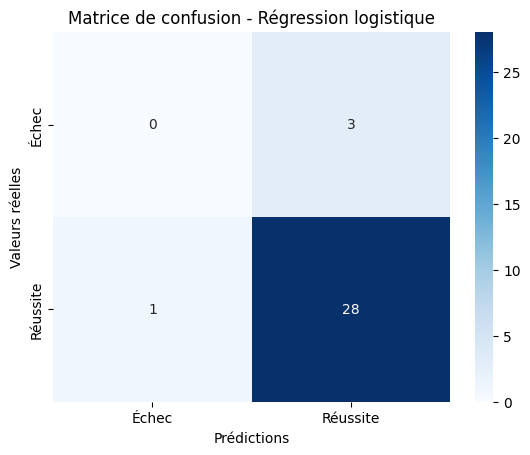


MODÈLE : KNN
Matrice de confusion :
[[ 0  3]
 [ 1 28]]

Rapport de classification :
              precision    recall  f1-score   support

       Échec       0.00      0.00      0.00         3
    Réussite       0.90      0.97      0.93        29

    accuracy                           0.88        32
   macro avg       0.45      0.48      0.47        32
weighted avg       0.82      0.88      0.85        32



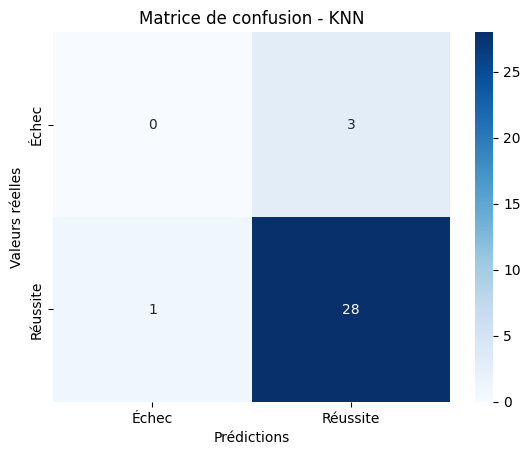


MODÈLE : Arbre de décision
Matrice de confusion :
[[ 2  1]
 [ 3 26]]

Rapport de classification :
              precision    recall  f1-score   support

       Échec       0.40      0.67      0.50         3
    Réussite       0.96      0.90      0.93        29

    accuracy                           0.88        32
   macro avg       0.68      0.78      0.71        32
weighted avg       0.91      0.88      0.89        32



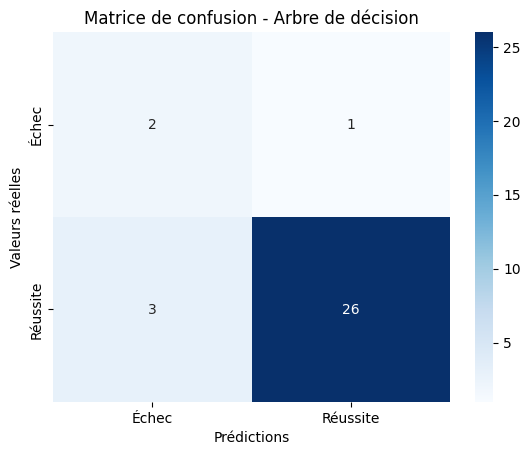


MODÈLE : SVM
Matrice de confusion :
[[ 3  0]
 [ 8 21]]

Rapport de classification :
              precision    recall  f1-score   support

       Échec       0.27      1.00      0.43         3
    Réussite       1.00      0.72      0.84        29

    accuracy                           0.75        32
   macro avg       0.64      0.86      0.63        32
weighted avg       0.93      0.75      0.80        32



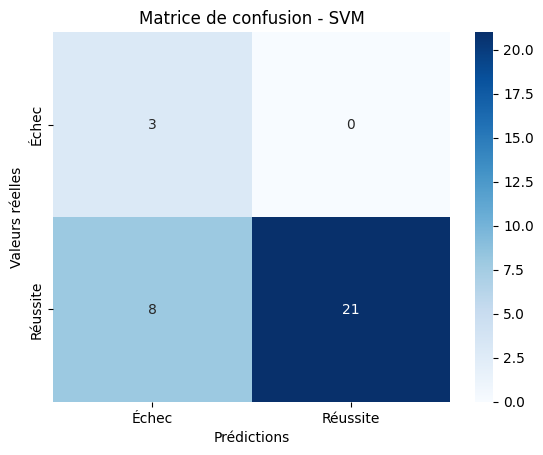

In [31]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    print("\n", "=" * 50)
    print("MODÈLE :", name)
    print("Matrice de confusion :")
    print(cm)

    print("\nRapport de classification :")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Échec", "Réussite"],
        zero_division=0
    ))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Échec", "Réussite"],
        yticklabels=["Échec", "Réussite"]
    )

    plt.title("Matrice de confusion - " + name)
    plt.xlabel("Prédictions")
    plt.ylabel("Valeurs réelles")
    plt.show()


In [32]:

from sklearn.metrics import balanced_accuracy_score

comparison = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    comparison.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "F1 Réussite": f1_score(y_test, predictions, pos_label=1),
        "F1 Échec": f1_score(y_test, predictions, pos_label=0)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))


,Modèle,Accuracy,Balanced Accuracy,F1 Réussite,F1 Échec
0,Régression logistique,0.875,0.483,0.933,0.000
1,KNN,0.875,0.483,0.933,0.000
2,Arbre de décision,0.875,0.782,0.929,0.500
3,SVM,0.750,0.862,0.840,0.429


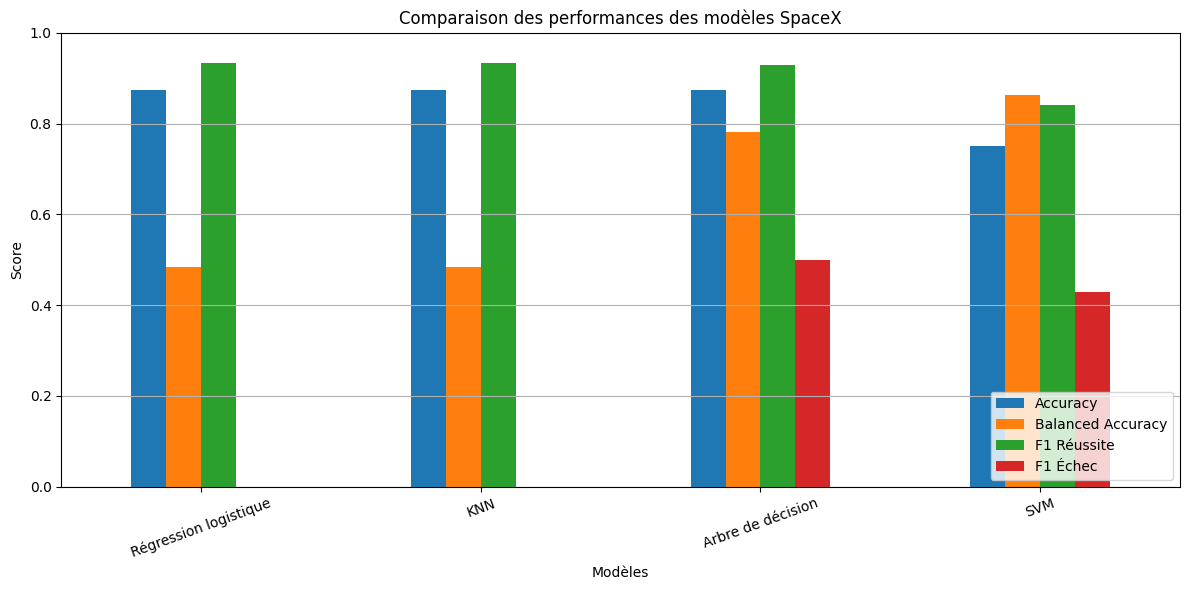

In [33]:

comparison_plot = comparison_df.set_index("Modèle")

comparison_plot[
    ["Accuracy", "Balanced Accuracy", "F1 Réussite", "F1 Échec"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparaison des performances des modèles SpaceX")
plt.ylabel("Score")
plt.xlabel("Modèles")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [34]:

import joblib
import os

os.makedirs("models", exist_ok=True)

best_model = trained_models["Arbre de décision"]

joblib.dump(
    best_model,
    "models/spacex_landing_prediction_model.pkl"
)

print("Modèle enregistré avec succès !")


Modèle enregistré avec succès !
